BÀI 1

# THỰC HÀNH XÂY DỰNG MÔ HÌNH CLASSIFICATION VỚI DỮ LIỆU BẢNG

### Bài toán
Xây dựng mô hình **phân loại nhị phân** để nhận diện mẫu thuộc lớp **malignant** từ bộ dữ liệu Breast Cancer Wisconsin của `scikit-learn`.

Bài này đi vào quy trình xây dựng và đánh giá mô hình classification khi dữ liệu bị **class imbalance**.

### Mục tiêu
- Nhận biết một bài toán **binary classification**.
- Phân tích mức độ **mất cân bằng lớp**.
- Hiểu vì sao **Accuracy có thể gây hiểu nhầm** khi dữ liệu imbalance.
- Chia dữ liệu bằng `train_test_split(..., stratify=y)`.
- Hiểu và sử dụng **StandardScaler** đúng cách.
- Hiểu nguyên lý **K-Fold Cross Validation**.
- Phân biệt `KFold` và `StratifiedKFold`.
- Đánh giá mô hình bằng Accuracy, Precision, Recall, F1-score, ROC-AUC và PR-AUC.
- Áp dụng:
  - Random Over-Sampling;
  - Random Under-Sampling;
  - SMOTE.
- Kết hợp chuẩn hóa + sampling + model bằng **Pipeline** để tránh **data leakage**.
- So sánh các phương án bằng Cross Validation trước khi đánh giá trên tập test.

# PHẦN 1. CHUẨN BỊ MÔI TRƯỜNG & KHỞI TẠO

## Bước 1. Cài đặt và import thư viện

In [6]:
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.datasets import load_breast_cancer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    KFold,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.preprocessing import StandardScaler

from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler

RANDOM_STATE = 42

## Bước 2. Nạp dữ liệu Breast Cancer Wisconsin

In [7]:
cancer = load_breast_cancer(as_frame=True)
X_full = cancer.data.copy()
y_full = (cancer.target == 0).astype(int)  # 1 = malignant, 0 = benign
df_full = X_full.copy()
df_full["target"] = y_full

# Tạo dataset mất cân bằng (Imbalanced dataset)
benign_df = df_full[df_full["target"] == 0]
malignant_df = df_full[df_full["target"] == 1].sample(
    n=60, random_state=RANDOM_STATE
)
df = pd.concat([benign_df, malignant_df], axis=0)
df = df.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,14.26,18.17,91.22,633.1,0.06576,0.05220,0.02475,0.01374,0.1635,0.05586,...,25.26,105.80,819.7,0.09445,0.21670,0.15650,0.07530,0.2636,0.07676,0
1,19.53,32.47,128.00,1223.0,0.08420,0.11300,0.11450,0.06637,0.1428,0.05313,...,45.41,180.20,2477.0,0.14080,0.40970,0.39950,0.16250,0.2713,0.07568,1
2,15.34,14.26,102.50,704.4,0.10730,0.21350,0.20770,0.09756,0.2521,0.07032,...,19.08,125.10,980.9,0.13900,0.59540,0.63050,0.23930,0.4667,0.09946,1
3,9.72,18.22,60.73,288.1,0.06950,0.02344,0.00000,0.00000,0.1653,0.06447,...,20.83,62.25,303.8,0.07117,0.02729,0.00000,0.00000,0.1909,0.06559,0
4,11.15,13.08,70.87,381.9,0.09754,0.05113,0.01982,0.01786,0.1830,0.06105,...,16.30,76.25,440.8,0.13410,0.08971,0.07116,0.05506,0.2859,0.06772,0


# PHẦN 2. PHÂN TÍCH VÀ CHIA DỮ LIỆU (TRAIN / TEST SPLIT)

## Bước 3. Kiểm tra phân bố lớp và chia Stratified Split

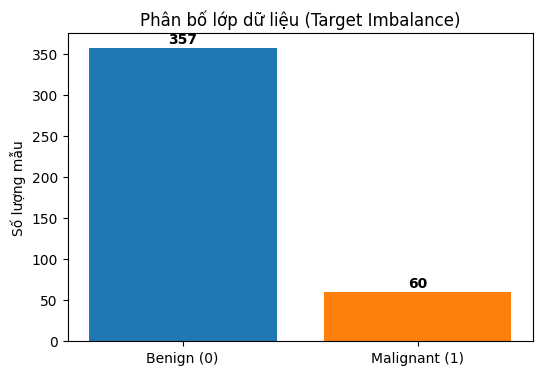

Kích thước tập Train: (333, 30)
Kích thước tập Test: (84, 30)


In [8]:
# Trực quan hóa phân bố lớp
fig, ax = plt.subplots(figsize=(6, 4))
counts = df["target"].value_counts()
ax.bar(["Benign (0)", "Malignant (1)"], counts.values, color=["#1f77b4", "#ff7f0e"])
ax.set_ylabel("Số lượng mẫu")
ax.set_title("Phân bố lớp dữ liệu (Target Imbalance)")
for i, v in enumerate(counts.values):
  ax.text(i, v + 5, str(v), ha="center", fontweight="bold")
plt.show()

# Chia tập train/test bảo toàn tỷ lệ lớp (Stratify)
X = df.drop(columns="target")
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Kích thước tập Train:", X_train.shape)
print("Kích thước tập Test:", X_test.shape)

# PHẦN 3. ĐÁNH GIÁ MÔ HÌNH BẰNG CROSS VALIDATION & PIPELINE

## Bước 4. Xây dựng Pipeline và chạy Stratified 10-Fold Cross Validation

In [9]:
models = {
    "No Sampling": ImbPipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
    ]),
    "Random OverSampling": ImbPipeline([
        ("scaler", StandardScaler()),
        ("sampler", RandomOverSampler(random_state=RANDOM_STATE)),
        ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
    ]),
    "Random UnderSampling": ImbPipeline([
        ("scaler", StandardScaler()),
        ("sampler", RandomUnderSampler(random_state=RANDOM_STATE)),
        ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
    ]),
    "SMOTE": ImbPipeline([
        ("scaler", StandardScaler()),
        ("sampler", SMOTE(random_state=RANDOM_STATE)),
        ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
    ]),
}

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
}

cv_results_dict = {}
for name, pipeline in models.items():
  scores = cross_validate(
      pipeline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1
  )
  cv_results_dict[name] = {
      "Accuracy": scores["test_accuracy"].mean(),
      "Precision": scores["test_precision"].mean(),
      "Recall": scores["test_recall"].mean(),
      "F1-Score": scores["test_f1"].mean(),
      "ROC-AUC": scores["test_roc_auc"].mean(),
  }

cv_comparison = pd.DataFrame(cv_results_dict).T
cv_comparison.round(4)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
No Sampling,0.988,0.9667,0.955,0.9564,0.9957
Random OverSampling,0.988,0.9667,0.955,0.9564,0.9953
Random UnderSampling,0.985,0.9500,0.955,0.9473,0.9952
SMOTE,0.988,0.9667,0.955,0.9564,0.9966


# PHẦN 4. ĐÁNH GIÁ TRÊN TẬP TEST & ĐỒ THỊ TRỰC QUAN

## Bước 5. Chọn mô hình tốt nhất và kiểm tra tập Hold-out Test

Mô hình được lựa chọn dựa trên F1-Score: No Sampling

--- CLASSIFICATION REPORT ---
               precision    recall  f1-score   support

   Benign (0)       0.99      1.00      0.99        72
Malignant (1)       1.00      0.92      0.96        12

     accuracy                           0.99        84
    macro avg       0.99      0.96      0.97        84
 weighted avg       0.99      0.99      0.99        84



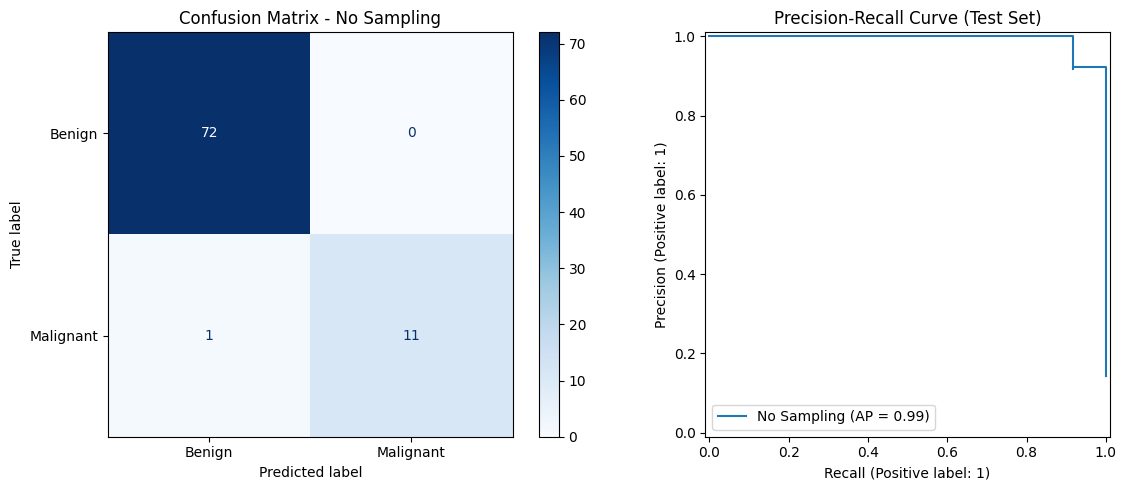

In [10]:
selection_metric = "F1-Score"
best_name = cv_comparison[selection_metric].idxmax()
best_model = models[best_name]

# Huấn luyện trên toàn bộ tập train
best_model.fit(X_train, y_train)

# Dự đoán tập Test
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

print(f"Mô hình được lựa chọn dựa trên {selection_metric}: {best_name}\n")
print("--- CLASSIFICATION REPORT ---")
print(
    classification_report(
        y_test, y_pred, target_names=["Benign (0)", "Malignant (1)"]
    )
)

# Trực quan Ma trận nhầm lẫn & Đường cong ROC
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_estimator(
    best_model,
    X_test,
    y_test,
    display_labels=["Benign", "Malignant"],
    cmap=plt.cm.Blues,
    ax=axes[0],
)
axes[0].set_title(f"Confusion Matrix - {best_name}")

PrecisionRecallDisplay.from_estimator(
    best_model, X_test, y_test, ax=axes[1], name=best_name
)
axes[1].set_title("Precision-Recall Curve (Test Set)")

plt.tight_layout()
plt.show()

BÀI 2

In [11]:
import warnings

warnings.filterwarnings("ignore")

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

RANDOM_STATE = 42


def main():
  print("1. Đang nạp và hợp nhất dữ liệu wine_quality_merged...")
  red_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
  white_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"

  try:
    df_red = pd.read_csv(red_url, sep=";")
    df_white = pd.read_csv(white_url, sep=";")
  except Exception as e:
    print(
        "Lỗi: Không thể tải dữ liệu từ internet. Kiểm tra lại kết nối mạng."
    )
    return

  # Thêm cột loại rượu (0: Red, 1: White)
  df_red["type"] = 0
  df_white["type"] = 1

  # Hợp nhất dữ liệu
  df_merged = pd.concat([df_red, df_white], ignore_index=True)
  df_merged["target"] = (df_merged["quality"] >= 6).astype(int)

  print(f"-> Tổng số mẫu dữ liệu: {len(df_merged)} mẫu.")

  # Chia tập train/test (80% - 20%)
  X = df_merged.drop(columns=["quality", "target"])
  y = df_merged["target"]

  X_train, X_test, y_train, y_test = train_test_split(
      X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
  )

  models = {
      "Logistic Regression": ImbPipeline([
          ("scaler", StandardScaler()),
          (
              "model",
              LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
          ),
      ]),
      "Logistic Regression + SMOTE": ImbPipeline([
          ("scaler", StandardScaler()),
          ("sampler", SMOTE(random_state=RANDOM_STATE)),
          (
              "model",
              LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
          ),
      ]),
      "Random Forest": ImbPipeline([
          ("scaler", StandardScaler()),
          (
              "model",
              RandomForestClassifier(
                  n_estimators=100, random_state=RANDOM_STATE
              ),
          ),
      ]),
      "SVM (RBF Kernel)": ImbPipeline([
          ("scaler", StandardScaler()),
          ("model", SVC(probability=True, random_state=RANDOM_STATE)),
      ]),
  }

  # 10-Fold Cross Validation
  print("2. Đang thực hiện 10-Fold Cross Validation...")
  cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
  scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

  cv_results_dict = {}
  for name, pipeline in models.items():
    scores = cross_validate(
        pipeline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1
    )
    cv_results_dict[name] = {
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-Score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean(),
    }

  cv_comparison = pd.DataFrame(cv_results_dict).T
  print("\n=================== BẢNG SO SÁNH 10-FOLD CV ===================")
  print(cv_comparison.round(4))

  # Fit & Đánh giá trên tập Test
  best_name = cv_comparison["F1-Score"].idxmax()
  best_model = models[best_name]

  print(f"\n3. Huấn luyện mô hình tốt nhất ({best_name}) trên tập Test...")
  best_model.fit(X_train, y_train)
  y_pred = best_model.predict(X_test)

  print("\n--- CLASSIFICATION REPORT (TẬP TEST) ---")
  print(
      classification_report(
          y_test, y_pred, target_names=["Rượu thường (0)", "Rượu ngon (1)"]
      )
  )

  cm = confusion_matrix(y_test, y_pred)
  print("--- MA TRẬN NHẦM LẪN (CONFUSION MATRIX) ---")
  print(f"True Negative  (Thường -> Thường): {cm[0][0]}")
  print(f"False Positive (Thường -> Ngon)  : {cm[0][1]}")
  print(f"False Negative (Ngon -> Thường)  : {cm[1][0]}")
  print(f"True Positive  (Ngon -> Ngon)     : {cm[1][1]}")


if __name__ == "__main__":
  main()

1. Đang nạp và hợp nhất dữ liệu wine_quality_merged...
-> Tổng số mẫu dữ liệu: 6497 mẫu.
2. Đang thực hiện 10-Fold Cross Validation...

=================== BẢNG SO SÁNH 10-FOLD CV ===================
                             Accuracy  Precision  Recall  F1-Score  ROC-AUC
Logistic Regression            0.7423     0.7696  0.8462    0.8060   0.8012
Logistic Regression + SMOTE    0.7260     0.8289  0.7146    0.7673   0.8012
Random Forest                  0.8226     0.8437  0.8836    0.8631   0.8965
SVM (RBF Kernel)               0.7672     0.7917  0.8581    0.8235   0.8315

3. Huấn luyện mô hình tốt nhất (Random Forest) trên tập Test...

--- CLASSIFICATION REPORT (TẬP TEST) ---
                 precision    recall  f1-score   support

Rượu thường (0)       0.82      0.74      0.78       477
  Rượu ngon (1)       0.86      0.91      0.88       823

       accuracy                           0.84      1300
      macro avg       0.84      0.82      0.83      1300
   weighted avg       0.84